<h2 style="text-align: center;"><b>Предсказание стоимости медицинских услуг клиента страховой компании</b></h2>

Задача: **построить модель, прогнозирующую стоимость медицинских услуг** клиента страховой компании

Данные: <a href="https://www.kaggle.com/datasets/mirichoi0218/insurance/data">Medical Costs Dataset</a>

содержат:
* возраст
* пол
* индекс массы тела
* количество детей
* статус курильщика
* регион проживания
* стоимость медицинских услуг

по более чем 1300 клиентам страховой компании. По этому набору данных нужно построить **модель прогноза стоимости медицинских услуг**.

<h3>Часть 1. Разведывательный анализ данных</h3>

В этом документе описаны:
* Первичный анализ данных 
* Анализ целевой переменной
* Анализ взаимосвязей между признаками
* Анализ взаимосвязей между целевой переменной и признаками
* Выводы разведывательного анализа

<h4>Данные. Загрузка и первичный анализ</h4>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Данные <a href="https://www.kaggle.com/datasets/mirichoi0218/insurance/data">Medical Costs Dataset</a> сохранены локально в папке data

In [2]:
df = pd.read_csv('data/insurance_medical_costs.csv')

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


В таблице: целевая переменная `charges` &ndash; стоимость медицинских услуг, числовые признаки: `age` (возраст), `bmi` (индекс массы тела), `children` (число детей), категориальные признаки: `sex`, `smoker`, `region`.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


Нулевых данных нет

In [5]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


Первичный анализ с помощью команды df.describe() даёт нам следующее:

**Целевая переменная**
* очень вариативна: стандартное отклонение std 12110 сравнимо со средним значением mean 13270 (округляю до единиц)
* половина данных charges располагается в диапазоне от 1122 до 9382
* три четверти данных charges не превосходят 16640
* у данных есть длинный "хвост" до 63770 &ndash; с ним нужно будет внимательно работать при построении прогноза

**Признаки**
* возраст: лежит в диапазоне от 18 до 64 (все клиенты совершеннолетние), средний возраст и медиана около 40 лет &ndash; почти точно середина диапазона
* индекс массы тела: средняя величина и медиана чуть выше 30, что лежит на границе медицинских категорий "Предожирение" и "Ожирение I степени". При этом согласно медицинской классификации этих терминов "Предожирение" считается изменяемым фактором риска, "Ожирение I степени" уже является диагнозом. Таким образом по показателю индекса массы тела половина клиентов здоровы
* число детей: медиана и среднее около 1, третий квартиль: 2, максимум: 5. Можно сделать вывод, что в нашей выборке много клиентов, у которых нет детей

<h4>Анализ целевой переменной</h4>

In [6]:
mean_charges = np.mean(df['charges'].values)
median_charges = np.quantile(df['charges'].values, q=0.5)
print(f"Среднее: {mean_charges:.2f}")
print(f"Медиана: {median_charges:.2f}")

Среднее: 13270.42
Медиана: 9382.03


Построим гистограмму распределения стоимости медицинских услуг

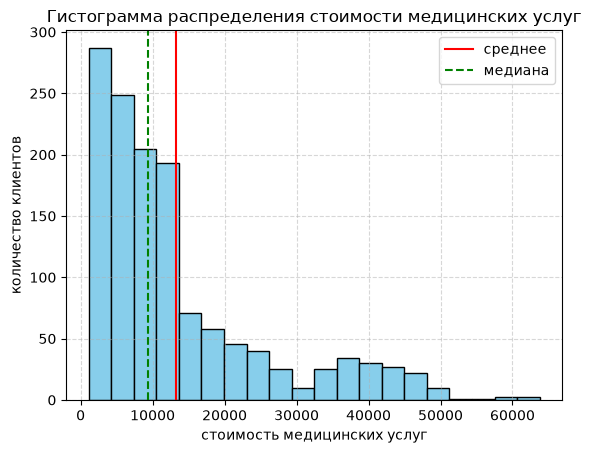

In [7]:
plt.hist(df['charges'], bins=20, color='skyblue', edgecolor='black')

plt.axvline(x=mean_charges, color='r', linestyle = '-', label='среднее')
plt.axvline(x=median_charges, color='g', linestyle = '--', label='медиана')

plt.title('Гистограмма распределения стоимости медицинских услуг')
plt.xlabel('стоимость медицинских услуг')
plt.ylabel('количество клиентов')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Выводы:** по гистограмме можно предположить, что примерно половина клиентов страховой компании &ndash; это люди, которые всего несколько раз в год пользуются медицинскими услугами (первая группа здоровья). Также у страховой компании есть, должно быть, клиенты с хроническими заболеваниями, которым требуется регулярное медицинское наблюдение и обслуживание. А также могут быть клиенты, которым мог потребоваться большой объём медицинского обслуживания ввиду несчастного случая.

**Ожидаемая сложность при прогнозировании:** при прогнозировании нужно будет проводить аккуратный выверенный подбор гиперпараметров, чтобы одновременно давать максимально точный прогноз и в среднестатистическом случае, и для случаев высокой стоимости медицинских услуг. Для страховой компании важно предсказывать случаи высоких медицинских затрат. Мы не имеем права отбрасывать сложные случаи. Следует постараться их предсказывать с наименьшим ущербом для оценки затрат в среднестатистическом случае.

<h4>Предобработка и анализ признаков</h4>

In [8]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<h5>Предобработка признака 'smoker'</h5>

In [9]:
df['smoker'].value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

In [10]:
df['smoker'] = df['smoker'].astype(str).str.strip().str.lower().replace({'yes': 1, 'no': 0})
df['smoker'] = pd.to_numeric(df['smoker'], errors='coerce')

In [11]:
df['smoker'].value_counts()

smoker
0    1064
1     274
Name: count, dtype: int64

<h5>Предобработка признака 'region'</h5>

In [12]:
df['region'].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

Заметим, что клиентов из всех регионов кроме региона southeast примерно одинаковое количество. Клиентов из региона southeast примерно на 10% больше чем клиентов из какого-либо другого региона.

Руководствуясь здравым смыслом, можно предположить, что регион клиента не является определяющим или важным признаком формирующим стоимость медицинских услуг клиента. Ниже мы проверим этот факт. А пока что используем простой LabelEncoder для преобразования строковых данных колонки 'region' в числа. Таким образом обработанный признак 'region' будет удобнее анализировать.

In [13]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

df['region_labeled'] = encoder.fit_transform(df['region'])

In [14]:
region_mapping = dict(zip(encoder.classes_, range(len(encoder.classes_))))
print(region_mapping)

{'northeast': 0, 'northwest': 1, 'southeast': 2, 'southwest': 3}


<h5>Предобработка оставшихся признаков</h5>

Преобразуем оставшиеся признаки (region, sex) с помощью OneHotEncoder

In [15]:
from sklearn.preprocessing import OneHotEncoder

In [16]:
cat_features_list = df.select_dtypes(include=['object', 'str']).columns

encoder = OneHotEncoder(sparse_output=False)
one_hot_encoded = encoder.fit_transform(df[cat_features_list])
one_hot_encoded = pd.DataFrame(one_hot_encoded, columns=encoder.get_feature_names_out(cat_features_list), index=df.index)

df = pd.concat([df, one_hot_encoded], axis=1)
df = df.drop(cat_features_list, axis=1)

Таблица приобрела следующий вид

In [17]:
df.head(3)

,age,bmi,children,smoker,charges,region_labeled,sex_female,sex_male,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.90,0,1,16884.9240,3,1.0,0.0,0.0,0.0,0.0,1.0
1,18,33.77,1,0,1725.5523,2,0.0,1.0,0.0,0.0,1.0,0.0
2,28,33.00,3,0,4449.4620,2,0.0,1.0,0.0,0.0,1.0,0.0


<h5>Сохранение файла</h5>

Сохраним таблицу в файл

In [18]:
df = df.rename(columns={'region_labeled': 'region'})

In [19]:
df.head()

,age,bmi,children,smoker,charges,region,sex_female,sex_male,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.900,0,1,16884.92400,3,1.0,0.0,0.0,0.0,0.0,1.0
1,18,33.770,1,0,1725.55230,2,0.0,1.0,0.0,0.0,1.0,0.0
2,28,33.000,3,0,4449.46200,2,0.0,1.0,0.0,0.0,1.0,0.0
3,33,22.705,0,0,21984.47061,1,0.0,1.0,0.0,1.0,0.0,0.0
4,32,28.880,0,0,3866.85520,1,0.0,1.0,0.0,1.0,0.0,0.0


In [20]:
df.to_csv('data/medical_costs_preprocessed.csv', index=False, encoding='utf-8-sig')

Для дальнейшего анализа удалим последние колонки

In [21]:
df = df.drop(columns=df.columns[df.columns.str.startswith("region_")])

In [22]:
df.head(3)

,age,bmi,children,smoker,charges,region,sex_female,sex_male
0,19,27.90,0,1,16884.9240,3,1.0,0.0
1,18,33.77,1,0,1725.5523,2,0.0,1.0
2,28,33.00,3,0,4449.4620,2,0.0,1.0


<h5>Анализ числовых признаков</h5>

In [23]:
numerical_columns = ['age', 'bmi']

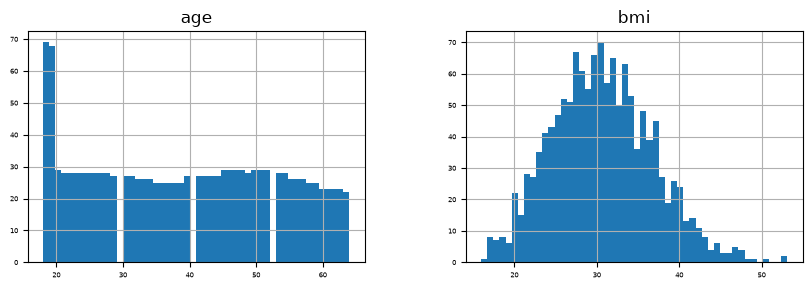

In [24]:
num_features = df[numerical_columns]

num_features.hist(figsize=(10, 3), bins=50, xlabelsize=5, ylabelsize=5, grid=True);

**Особенности**

Можно отметить, что распределение по возрасту клиентов близко к равномерному, за исключением всплеска 18-20 лет. Возможно, это новые клиенты страховой компании, специально таргетированная целевая аудитория.

Распределение клиентов по индексу массы тела близко к колоколообразному.

<h5>Корреляционная матрица</h5>

Рассмотрим корреляционную матрицу по всей таблице

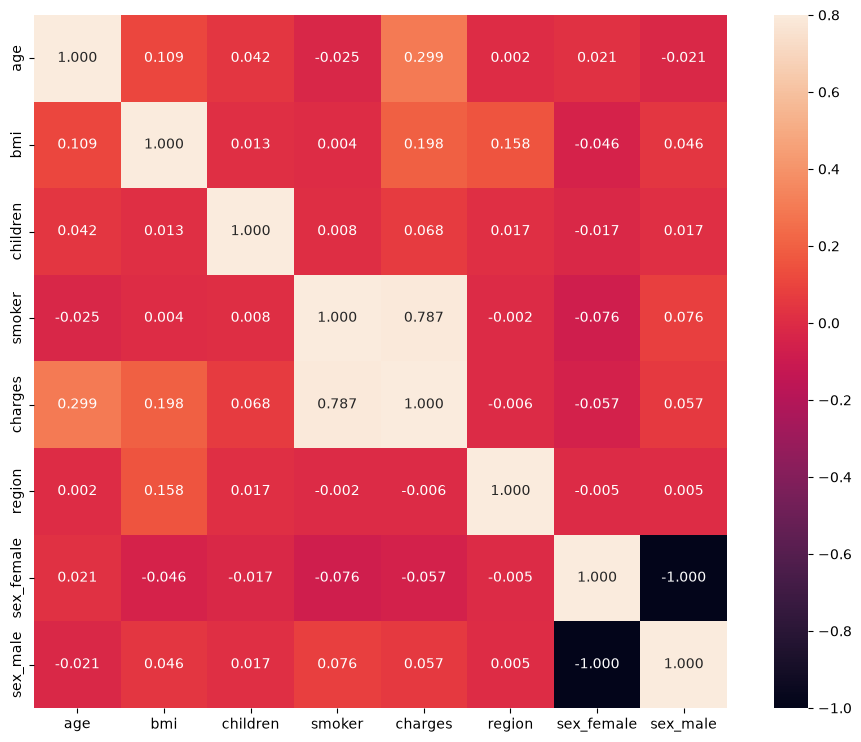

In [25]:
import seaborn as sns

corrmat = df.corr()
f, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corrmat, vmax=.8, square=True, annot=True, fmt='.3f');

**Особенности**

Отметим, что наблюдается **сильная корриляция** между признаком 'smoker' и целевой переменной 'charges' (0,79).

Есть очень слабая положительная связь между признаками 'bmi' и 'region'. Возможно, она связана с особенностями рациона.

Есть очень слабая корреляция между 'age' и 'bmi'. Это закономерно: часть людей с возрастом полнеют. А также между 'age' и 'charges', что тоже естественно.

Обратная корреляция (-1) между признаками sex_female и sex_male естественна: клиент относится строго к одному из полов.

**Существенной корреляции между признаками нет.** Что также подтверждается графиками ниже

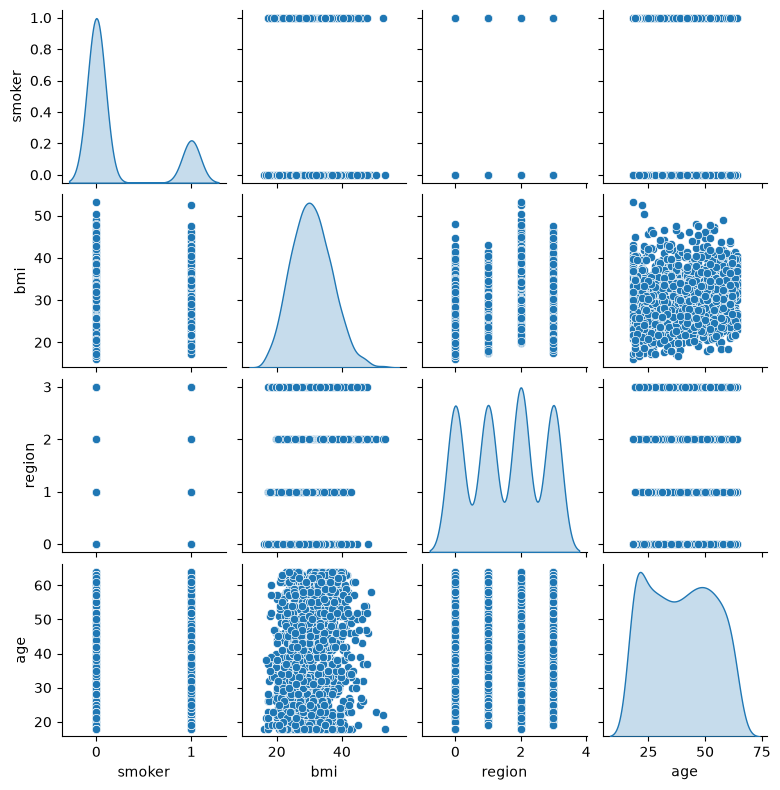

In [26]:
sns.pairplot(df, vars = ['smoker', 'bmi', 'region', 'age'], height = 2 , kind ='scatter', diag_kind='kde')
plt.show()

<h4>Анализ взаимосвязей между целевой переменной от признаками</h4>

<h5>Взаимосвязь целевой переменной и категориальных признаков</h5>

**Зависимость стоимости медицинских услуг от статуса курильщика**

Некурящих в нашей выборке в 3-4 раза больше, чем курящих

In [27]:
df['smoker'].value_counts()

smoker
0    1064
1     274
Name: count, dtype: int64

Построим диаграмму ящик с усами для целевой переменной для каждой из категорий ('курит'/'не курит')

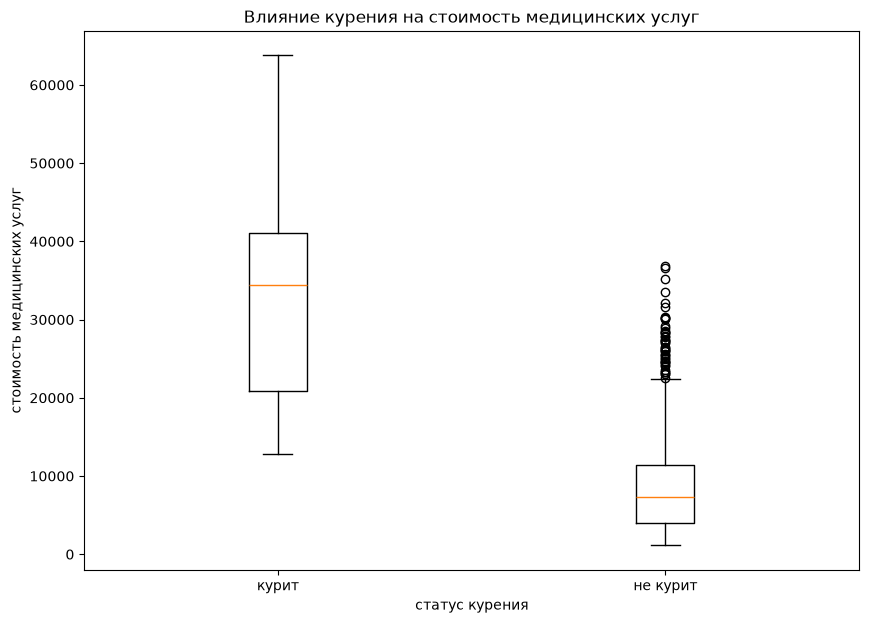

In [28]:
charges_smoker = df['charges'][df['smoker'] == 1]
charges_nonsmoker = df['charges'][df['smoker'] == 0]

charges_ylabel = 'стоимость медицинских услуг'

box_figsize = (10, 7)
plt.figure(figsize=box_figsize)

plt.boxplot([charges_smoker, charges_nonsmoker]);
plt.title('Влияние курения на стоимость медицинских услуг');
plt.xlabel('статус курения');
plt.ylabel(charges_ylabel);
plt.xticks([1, 2], ['курит', 'не курит']);


На диаграмме оранжевым цветом отмечены медианы стоимости медицинских услуг для курящих и некурящих клиентов соответственно. Нижняя граница каждого из ящиков соответствуют 25% от всех клиентов категории, верхняя &ndash; 75%.

Разница значительна: из диаграммы видно, что стоимость медицинских услуг 75% некурящих ниже, чем стоимость услуг 75% курящих. Диаграмма ещё раз подтверждает, что **статус курильщика один из значимых признаков при оценке стоимости медицинских услуг**.

**Зависимость стоимости медицинских услуг от пола**

In [29]:
charges_female = df['charges'][df['sex_female'] == 1]
charges_male = df['charges'][df['sex_male'] == 1]

In [30]:
median_female = np.quantile(charges_female.values, q=0.5)
median_male = np.quantile(charges_male.values, q=0.5)

In [31]:
print(f'число женщин: {charges_female.size}\nчисло мужчин: {charges_male.size}')

число женщин: 662
число мужчин: 676


In [32]:
print(f'медиана (женщины): {median_female}\nмедиана (мужчины): {median_male}')

медиана (женщины): 9412.9625
медиана (мужчины): 9369.61575


Мужчин и женщин в нашем наборе примерно поровну. Медианы двух категорий очень близки

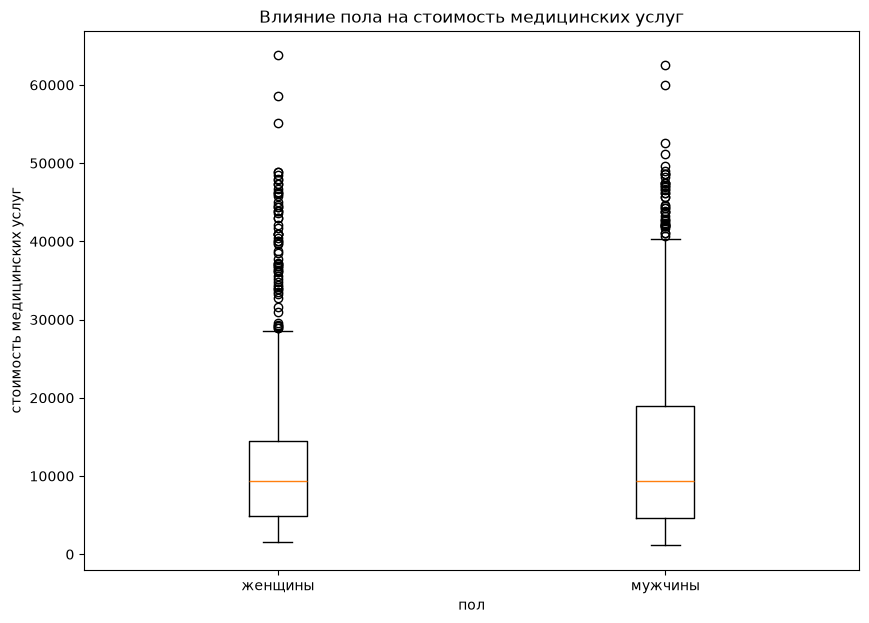

In [33]:
plt.figure(figsize=box_figsize)
plt.boxplot([charges_female, charges_male]);
plt.title('Влияние пола на стоимость медицинских услуг');
plt.xlabel('пол');
plt.ylabel(charges_ylabel);
plt.xticks([1, 2], ['женщины', 'мужчины']);

Медианы двух категорий близки между собой. Межквартильный размах для мужчин больше, чем для женщин &ndash; за счёт более высокого уровня третьего квартиля &ndash; границы 75%.

Примерно для 50% данных различия в стоимости услуг несущественны. Можно даже предположить, что пол может быть избыточным данным при обучении некоторых моделей.

**Взаимосвязь между стоимостью услуг и регионом**

In [34]:
region_mapping

{'northeast': 0, 'northwest': 1, 'southeast': 2, 'southwest': 3}

In [35]:
region_means = df.groupby('region')['charges'].mean()
region_means_dict = {k: round(float(region_means[v]), 2) for k, v in region_mapping.items()}
print('Средние значения стоимости медицинских услуг по регионам:')
print(region_means_dict)

Средние значения стоимости медицинских услуг по регионам:
{'northeast': 13406.38, 'northwest': 12417.58, 'southeast': 14735.41, 'southwest': 12346.94}


In [36]:
region_dist = df['region'].value_counts()
print(region_dist)

region
2    364
3    325
1    325
0    324
Name: count, dtype: int64


In [37]:
def get_region_labels(rg_dist, rg_map):
    return [label
            for j in rg_dist.index
            for label, i in rg_map.items()
            if i == j]

region_labels = get_region_labels(region_dist, region_mapping)
region_labels

['southeast', 'southwest', 'northwest', 'northeast']

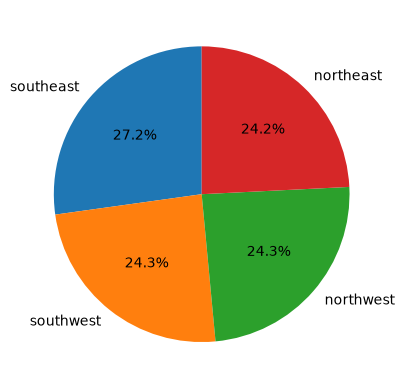

In [38]:
plt.pie(region_dist, autopct='%1.1f%%', labels=region_labels, startangle=90);

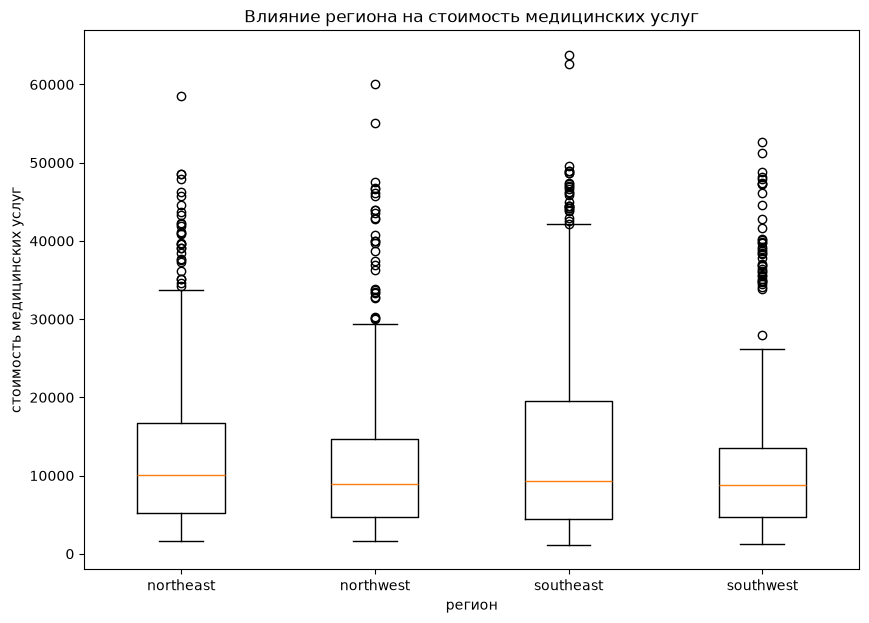

In [39]:
charges_region = [df['charges'][df['region'] == i] for i in region_mapping.values()]

plt.figure(figsize=box_figsize);
plt.boxplot(charges_region);
plt.title('Влияние региона на стоимость медицинских услуг');
plt.xlabel('регион');
plt.ylabel(charges_ylabel);
plt.xticks(range(1, len(region_mapping) + 1), region_mapping.keys());

Выводы:
* все регионы представлены равномерно (исключение: клиентов из southeast несколько больше, чем из других регионов)
* первая и вторая квартиль по всем регионам близки между собой
* **регион, возможно, является неинформативным признаком**, который может создавать шум при обучении

**Взаимосвязь между стоимостью услуг и количеством детей**

Представим схематично распределение по количеству детей

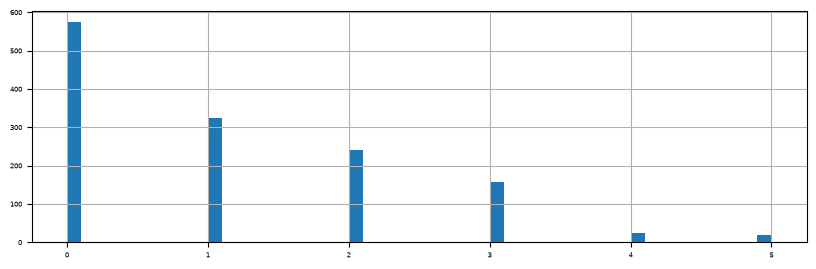

In [40]:
df['children'].hist(figsize=(10, 3), bins=50, xlabelsize=5, ylabelsize=5, grid=True);

In [41]:
df['children'].value_counts()

children
0    574
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64

Посмотрим на то, как влияет число детей на стоимость медицинских услуг клиента также в зависимости от пола родителей

In [42]:
children_max = df['children'].max()
children_range_max = children_max + 1
charges_female_children = [charges_female[df['children'] == i] for i in range(children_range_max)]
charges_male_children = [charges_male[df['children'] == i] for i in range(children_range_max)]
charges_children_all = [df['charges'][df['children'] == i] for i in range(children_range_max)]

charges_children = {'женщины': charges_female_children, 'мужчины': charges_male_children, 'все': charges_children_all}

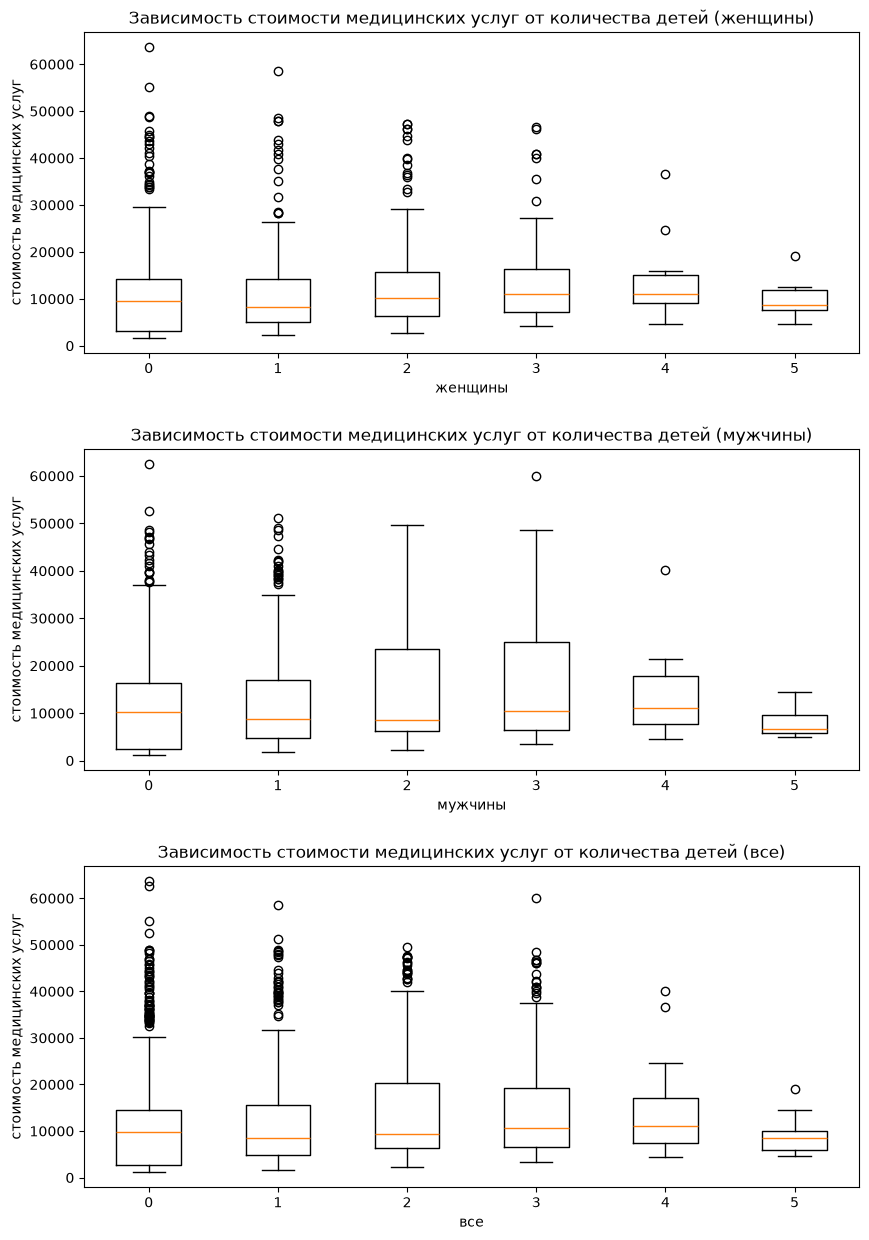

In [43]:
n_rows = len(charges_children)
fig, axes = plt.subplots(n_rows, 1, figsize=(10, 5 * n_rows), squeeze=False)
axes = axes.flatten()

for i, key in enumerate(charges_children):
    ax = axes[i]

    ax.boxplot(charges_children[key])
    ax.set_xlabel(key)
    ax.set_ylabel(charges_ylabel)
    ax.set_title(f'Зависимость стоимости медицинских услуг от количества детей ({key})')
    ax.set_xticks(range(1, children_range_max + 1), range(children_range_max))

plt.subplots_adjust(hspace=0.3)
plt.show()

Выводы:
* среди клиентов страховой компании больше всего клиентов без детей (574 человека)
* при большом количестве детей 4 и 5 мы имеем всего 25 и 18 клиентов, соответственно 
* количество детей информативный признак

**Взаимосвязь между стоимостью услуг и числовыми признаками**

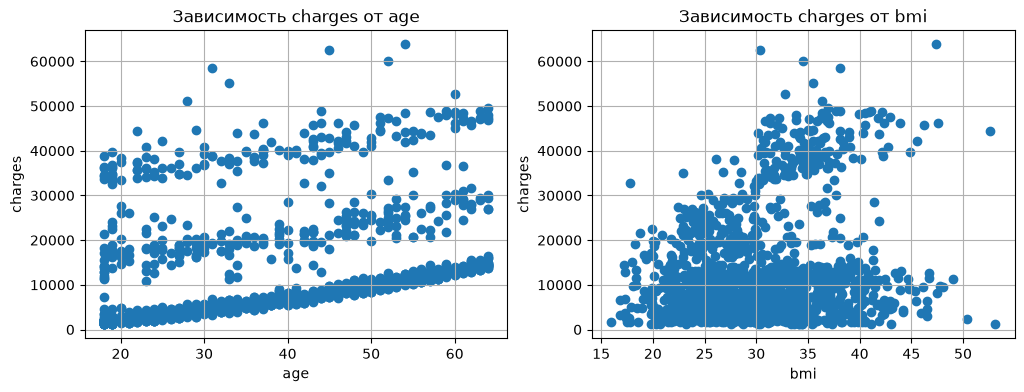

In [44]:
target = 'charges'
n_cols = len(numerical_columns)
n_rows = 1

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 4 * n_rows), squeeze=False)
axes = axes.flatten()

for i, feat in enumerate(num_features):
    ax = axes[i]
    ax.scatter(df[feat], df[target])
    ax.set_xlabel(feat)
    ax.set_ylabel(target)
    ax.set_title(f'Зависимость {target} от {feat}')
    ax.grid(True)

plt.show()

**Наблюдения:**
* примечательно, что на графике зависимости стоимости медицинских услуг от возраста видно три разных линейных тренда
* на графике зависимости стоимости медицинских услуг от индекса массы тела видна слабая линейная корреляция

**Уточнение данных по клиентам с высоким уровнем медицинских расходов**

Разобьём все данные на группы. Первые три группы соответствуют первым трём квартилям по стоимости медицинских услуг. Третья и четвёртая группа &ndash; это следующие 20%, разбитые пополам, последняя группа &ndash; оставшиеся 5%.

In [45]:
charges_qnt = np.quantile(df['charges'].values, [0, 0.25, 0.5, 0.75, 0.85, 0.95, 1])
print(charges_qnt)

[ 1121.8739     4740.28715    9382.033     16639.912515  24990.1669955
 41181.8277875 63770.42801  ]


In [46]:
df['group'] = pd.cut(df[target], bins=charges_qnt, include_lowest=True)

In [47]:
grouped = df.groupby('group')

display(grouped.size())

group
(1121.873, 4740.287]      335
(4740.287, 9382.033]      334
(9382.033, 16639.913]     334
(16639.913, 24990.167]    134
(24990.167, 41181.828]    134
(41181.828, 63770.428]     67
dtype: int64

Посмотрим на средние характеристики групп

In [48]:
display(grouped.mean().round(2))

,age,bmi,children,smoker,charges,region,sex_female,sex_male
group,,,,,,,,
"(1121.873, 4740.287]",23.81,29.91,0.62,0.00,2853.09,1.54,0.48,0.52
"(4740.287, 9382.033]",40.23,30.32,1.52,0.00,6991.86,1.59,0.51,0.49
"(9382.033, 16639.913]",52.64,31.11,1.06,0.06,12106.07,1.44,0.55,0.45
"(16639.913, 24990.167]",36.72,27.70,1.26,0.65,20571.65,1.37,0.49,0.51
"(24990.167, 41181.828]",38.57,32.07,1.07,0.75,33906.82,1.53,0.41,0.59
"(41181.828, 63770.428]",50.36,37.01,1.24,1.00,46585.29,1.64,0.39,0.61


**Наблюдения:**
* средний статус курильщика строго возрастает от 0 до 1
* средние характеристики возраста и количества детей не показывают *линейного* тренда
* По признаку индекса массы тела ('bmi') средние значения по всем группам близки к 30, за исключением группы последних 5%
* распределение по полам практически равномерное, за исключением последних 5%

Проверим равномерность распределения по регионам в каждой из выделенных групп

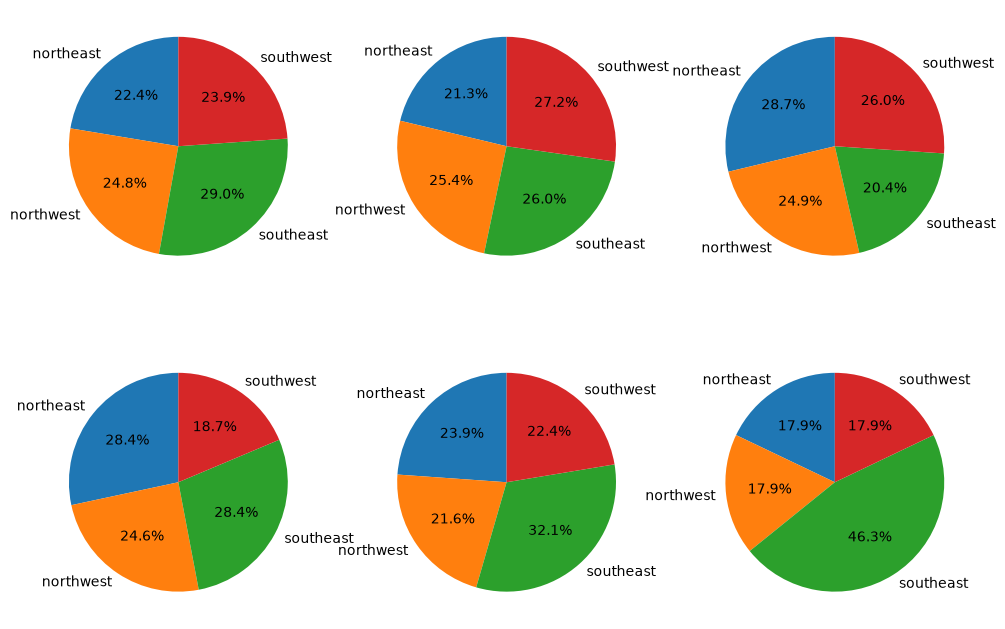

In [49]:
n_cols = 3
n_rows = len(df.groupby('group')) // n_cols + (len(df.groupby('group')) % n_cols != 0)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 4 * n_rows), squeeze=False)
axes = axes.flatten()

for i, (group_name, group_df) in enumerate(grouped):
    ax = axes[i]

    region_counts = group_df['region'].value_counts().sort_index()

    ax.pie(region_counts, labels=get_region_labels(region_counts, region_mapping), autopct='%1.1f%%', startangle=90)

Распределение клиентов по регионам в первых трёх группах (первые три квантиля) близко к равномерному. В последних двух группах (15% всех клиентов) &ndash; клиенты с самой высокой стоимостью медицинских услуг преобладают клиенты из региона southeast

Посмотрим пристальнее на последнюю группу &ndash; это 5% клиентов с максимальной стоимостью медицинских услуг, диапазон (41181.828, 63770.428]

In [50]:
last_group_df = df[df['group'] == df['group'].max()]

In [51]:
len(last_group_df)

67

In [52]:
last_group_df[last_group_df['smoker'] == 0]

,age,bmi,children,smoker,charges,region,sex_female,sex_male,group


In [53]:
last_group_df[last_group_df['children'] > 3]

,age,bmi,children,smoker,charges,region,sex_female,sex_male,group


In [54]:
last_group_df[last_group_df['bmi'] < 25]

,age,bmi,children,smoker,charges,region,sex_female,sex_male,group


In [55]:
last_group_df[last_group_df['age'] < 35]

,age,bmi,children,smoker,charges,region,sex_female,sex_male,group
34,28,36.400,1,1,51194.55914,3,0.0,1.0,"(41181.828, 63770.428]"
292,25,45.540,2,1,42112.23560,2,0.0,1.0,"(41181.828, 63770.428]"
577,31,38.095,1,1,58571.07448,0,1.0,0.0,"(41181.828, 63770.428]"
587,34,30.210,1,1,43943.87610,1,1.0,0.0,"(41181.828, 63770.428]"
739,29,35.500,2,1,44585.45587,3,0.0,1.0,"(41181.828, 63770.428]"
819,33,35.530,0,1,55135.40209,1,1.0,0.0,"(41181.828, 63770.428]"
1047,22,52.580,1,1,44501.39820,2,0.0,1.0,"(41181.828, 63770.428]"


In [56]:
region_mapping

{'northeast': 0, 'northwest': 1, 'southeast': 2, 'southwest': 3}

**Итого,** 67 человек (5% от всех) с самыми высокими расходами на медицинские услуги:
* **ВСЕ курят**
* имеют не более 3 детей
* их ИМТ больше 25 (выше нормы)

<h4>Выводы разведывательного анализа</h4>

На основе анализа можно ранжировать признаки по их значимости:
* числовые:
    * возраст, индекс массы тела (bmi) &ndash; примерно одинаково релевантны, корреляция с целевой переменной слабая
    * количество детей &ndash; релевантный дискретный числовой признак
* категориальные:
    * **статус курильщика** &ndash; значимый признак: **корреляция с целевой переменной: 0.79**
    * пол &ndash; менее важный признак
    * регион &ndash; малорелевантный, возможно, избыточный

Ввиду отсутствия явных зависимостей (линейной или полиномиальной) между признаками и целевой переменной, поставленную задачу регрессии (предсказания стоимости медицинских услуг) имеет смысл реализовать с помощью ансамблевых алгоритмов основывающихся на решающих деревьях. В качестве первого приближения можно также рассмотреть модель k ближайших соседей

Таким образом, **модели для прогноза стоимости медицинских услуг**, согласно предполагаемой эффективности:
* k-Nearest Neighbors &ndash; самый быстрый, годится как первое приближение, для сравнения с более сложными алгоритмами
* Random Forest Regressor
* Gradient Boosting &ndash; будет требовать наибольших ресурсов и наиболее аккуратной настройки

**Метрики** для оценки моделей:
* Mean Absolute Error &ndash; для оценки среднего отклонения от истинных значений
* Mean Absolute Percentage Error &ndash; безразмерная оценка относительно величины целевых значений
* Root Mean Squared Error &ndash; для более точного приближения экстремально больших значений